In [2]:
import pandas as pd
from scipy.stats import linregress, pearsonr

# 读取数据
df = pd.read_csv("F:/TUB/greenlandProject/ERA5LAND/MonthlyFeatures/1995prediction/ssrdt2mMEAN.csv")

# 将 yyyymm 转换为连续时间变量（如199501→1995.0 + 1/12）
df['time'] = df['yyyymm'].astype(str).str[:4].astype(int) + (df['yyyymm'] % 100 - 1) / 12

# 要分析的变量
vars_to_check = ['ssrd', 't2m', 'albedo','tcc']

# 计算各变量的趋势（线性回归斜率）
print("📈 各变量时间趋势（单位/年）:")
for var in vars_to_check:
    slope, intercept, r_value, p_value, std_err = linregress(df['time'], df[var])
    print(f"{var}: slope={slope:.4f}, R²={r_value**2:.3f}, p={p_value:.3g}")

# 计算变量间的相关性
print("\n🔗 变量间相关性（皮尔逊相关系数）:")
for i in range(len(vars_to_check)):
    for j in range(i+1, len(vars_to_check)):
        var1, var2 = vars_to_check[i], vars_to_check[j]
        corr, pval = pearsonr(df[var1], df[var2])
        print(f"{var1} vs {var2}: r={corr:.3f}, p={pval:.3g}")


📈 各变量时间趋势（单位/年）:
ssrd: slope=-19692.0163, R²=0.003, p=0.254
t2m: slope=0.0270, R²=0.008, p=0.0518
albedo: slope=0.0001, R²=0.001, p=0.482
tcc: slope=0.0005, R²=0.046, p=3.96e-06

🔗 变量间相关性（皮尔逊相关系数）:
ssrd vs t2m: r=0.504, p=2.02e-30
ssrd vs albedo: r=-0.115, p=0.0143
ssrd vs tcc: r=-0.501, p=5.58e-30
t2m vs albedo: r=-0.821, p=3.63e-111
t2m vs tcc: r=0.085, p=0.0724
albedo vs tcc: r=-0.238, p=3.3e-07


In [3]:
import pandas as pd
from scipy.stats import linregress

# 读取数据
df = pd.read_csv("F:/TUB/greenlandProject/ERA5LAND/MonthlyFeatures/1995prediction/ssrdt2mMEAN.csv")

# 提取年份与月份
df['year'] = df['yyyymm'] // 100
df['month'] = df['yyyymm'] % 100

# 分析的变量和月份
vars_to_check = ['ssrd', 't2m', 'albedo','tcc']
months = [4, 5, 6, 7, 8, 9]

print("📅 各月份各变量趋势（单位/年）:")
for var in vars_to_check:
    print(f"\n🔸 变量: {var}")
    for m in months:
        sub = df[df['month'] == m]
        slope, intercept, r_value, p_value, std_err = linregress(sub['year'], sub[var])
        print(f"Month {m}: slope={slope:.4f}, R²={r_value**2:.3f}, p={p_value:.3g}")


📅 各月份各变量趋势（单位/年）:

🔸 变量: ssrd
Month 4: slope=-9572.7836, R²=0.039, p=0.0879
Month 5: slope=-14024.9208, R²=0.031, p=0.129
Month 6: slope=-27519.4610, R²=0.084, p=0.0116
Month 7: slope=-24131.3964, R²=0.078, p=0.0156
Month 8: slope=-23093.3981, R²=0.153, p=0.000512
Month 9: slope=-13991.2574, R²=0.141, p=0.000883

🔸 变量: t2m
Month 4: slope=0.0413, R²=0.197, p=6.64e-05
Month 5: slope=0.0077, R²=0.011, p=0.379
Month 6: slope=0.0260, R²=0.179, p=0.000156
Month 7: slope=0.0272, R²=0.378, p=4.46e-09
Month 8: slope=0.0306, R²=0.277, p=1.21e-06
Month 9: slope=0.0236, R²=0.083, p=0.0121

🔸 变量: albedo
Month 4: slope=0.0003, R²=0.211, p=3.45e-05
Month 5: slope=0.0002, R²=0.210, p=3.48e-05
Month 6: slope=0.0000, R²=0.010, p=0.393
Month 7: slope=-0.0001, R²=0.066, p=0.0264
Month 8: slope=-0.0001, R²=0.092, p=0.00829
Month 9: slope=0.0002, R²=0.063, p=0.0304

🔸 变量: tcc
Month 4: slope=0.0006, R²=0.087, p=0.01
Month 5: slope=0.0004, R²=0.048, p=0.0587
Month 6: slope=0.0008, R²=0.117, p=0.00269
Month 7:

In [ ]:
import sys
sys.setrecursionlimit(2000)

import pandas as pd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from scipy.stats import linregress
import gc
import datetime

# === 0. 参数配置 ===
data_dir = r"F:\TUB\greenlandProject\ERA5LAND\MonthlyFeatures\1995prediction"
start_year_analysis = 1950
end_year_analysis = 2024
target_variable = 't2m'
selected_months = [7]  # 可设置为 [6, 7] 表示6-7月平均

# === 1. 获取空间网格信息 ===
def get_spatial_grid_info():
    for year in range(start_year_analysis, end_year_analysis + 1):
        for month in selected_months:
            file_name = f"{year:04d}{month:02d}prediction_clip.csv"
            file_path = os.path.join(data_dir, file_name)
            if os.path.exists(file_path):
                df = pd.read_csv(file_path, usecols=['latitude', 'longitude'])
                return np.sort(df['latitude'].unique()), np.sort(df['longitude'].unique())
    raise FileNotFoundError("找不到任何数据文件")

# === 2. 构建 Dataset ===
def read_data_efficiently():
    lats, lons = get_spatial_grid_info()
    years = list(range(start_year_analysis, end_year_analysis + 1))
    time_coords = pd.to_datetime([f"{y}-{selected_months[0]:02d}-15" for y in years])
    data_array = np.full((len(years), len(lats), len(lons)), np.nan, dtype=np.float32)
    lat_idx = {lat: i for i, lat in enumerate(lats)}
    lon_idx = {lon: i for i, lon in enumerate(lons)}

    for year_idx, year in enumerate(years):
        month_values = []
        for month in selected_months:
            file_name = f"{year:04d}{month:02d}prediction_clip.csv"
            file_path = os.path.join(data_dir, file_name)
            if os.path.exists(file_path):
                df = pd.read_csv(file_path, usecols=['latitude', 'longitude', target_variable])
                if df[target_variable].mean() > 200:
                    df[target_variable] -= 273.15
                month_values.append(df)
        if month_values:
            df_all = pd.concat(month_values).groupby(['latitude', 'longitude']).mean().reset_index()
            for _, row in df_all.iterrows():
                i = lat_idx.get(row['latitude'])
                j = lon_idx.get(row['longitude'])
                if i is not None and j is not None:
                    data_array[year_idx, i, j] = row[target_variable]
            del df_all
            gc.collect()

    ds = xr.Dataset(
        {target_variable: (['time', 'latitude', 'longitude'], data_array)},
        coords={'time': time_coords, 'latitude': lats, 'longitude': lons}
    )
    return ds

# === 3. 格点趋势计算 ===
def calculate_trends_chunked(ds):
    lats = ds['latitude'].values
    lons = ds['longitude'].values
    years = ds['time.year'].values
    trend = np.full((len(lats), len(lons)), np.nan, dtype=np.float32)

    for i in range(len(lats)):
        for j in range(len(lons)):
            y = ds[target_variable][:, i, j].values
            mask = np.isfinite(y)
            if mask.sum() > 1:
                slope, _, _, _, _ = linregress(years[mask], y[mask])
                trend[i, j] = slope

    return xr.DataArray(trend, coords={'latitude': lats, 'longitude': lons},
                        dims=['latitude', 'longitude'], name='Trend', attrs={'units': '°C/year'})

# === 4. 区域滑动趋势计算 ===
def calculate_sliding_window_trends(ds, min_window_length):
    regional_mean = ds[target_variable].mean(dim=['latitude', 'longitude']).sortby('time')
    years = regional_mean['time.year'].values
    values = regional_mean.values
    all_years = np.arange(years.min(), years.max() + 1)
    trend_matrix = np.full((len(all_years), len(all_years)), np.nan, dtype=np.float32)

    for i, start_y in enumerate(all_years):
        for j, end_y in enumerate(all_years):
            if end_y >= start_y + min_window_length - 1:
                mask = (years >= start_y) & (years <= end_y)
                y = values[mask]
                x = years[mask]
                valid = np.isfinite(y)
                if valid.sum() > 1:
                    slope, _, _, _, _ = linregress(x[valid], y[valid])
                    trend_matrix[j, i] = slope
    return trend_matrix, all_years

# === 5. 主流程 ===
ds = read_data_efficiently()

# 图(a) 平均温度分布图
avg_temp = ds[target_variable].mean(dim='time')
plt.figure(figsize=(10, 8))
avg_temp.plot(cmap='coolwarm', cbar_kwargs={'label': 'Average Temperature (°C)'})
plt.title(f'Greenland Average Temperature in {selected_months} ({start_year_analysis}-{end_year_analysis})')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()
plt.savefig('Greenland_Temp_July_meanT2C.png', dpi=300, bbox_inches='tight')
# 图(b) 温度趋势图
trend_map = calculate_trends_chunked(ds)
plt.figure(figsize=(10, 8))
trend_map.plot(cmap='RdBu_r', center=0, vmin=-0.1, vmax=0.1,
               cbar_kwargs={'label': 'Temperature Trend (°C/year)'})
plt.title(f'Greenland Temperature Trend in {selected_months} ({start_year_analysis}-{end_year_analysis})')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()
plt.savefig('Greenland_Temp_July_trendT2C.png', dpi=300, bbox_inches='tight')
# 图(c) 区域平均滑动趋势热图（支持单年）
region_mean = ds[target_variable].mean(dim=['latitude', 'longitude'])
years = ds['time.year'].values
trend_matrix = np.full((len(years), len(years)), np.nan)

for i, start in enumerate(years):
    for j, end in enumerate(years):
        if end >= start:
            mask = (years >= start) & (years <= end)
            x = years[mask]
            y = region_mean.sel(time=ds.time[mask]).values
            valid = np.isfinite(y)
            if valid.sum() > 1:
                slope, _, _, _, _ = linregress(x[valid], y[valid])
                trend_matrix[j, i] = slope
            elif end == start:
                trend_matrix[j, i] = 0.0

plt.figure(figsize=(12, 10))
ax = sns.heatmap(trend_matrix, cmap='RdBu_r', center=0, square=True,
                 vmin=-0.2, vmax=0.2,
                 cbar_kws={'label': 'Temperature Trend (°C/year)'})
tick_idx = np.arange(0, len(years), 5)
tick_labels = [str(years[i]) for i in tick_idx]

ax.set_xticks(tick_idx + 0.5)
ax.set_xticklabels(tick_labels, rotation=45, ha='right')
ax.set_yticks(tick_idx + 0.5)
ax.set_yticklabels(tick_labels, rotation=0, va='center')

plt.xlabel('Start Year')
plt.ylabel('End Year')
plt.title('Greenland Regional Temperature Trend (Sliding Window, single year included)')
plt.tight_layout()
plt.savefig('Greenland_Temp_July_Sliding_Trend_RdBu_fullrange.png', dpi=300, bbox_inches='tight')
plt.show()


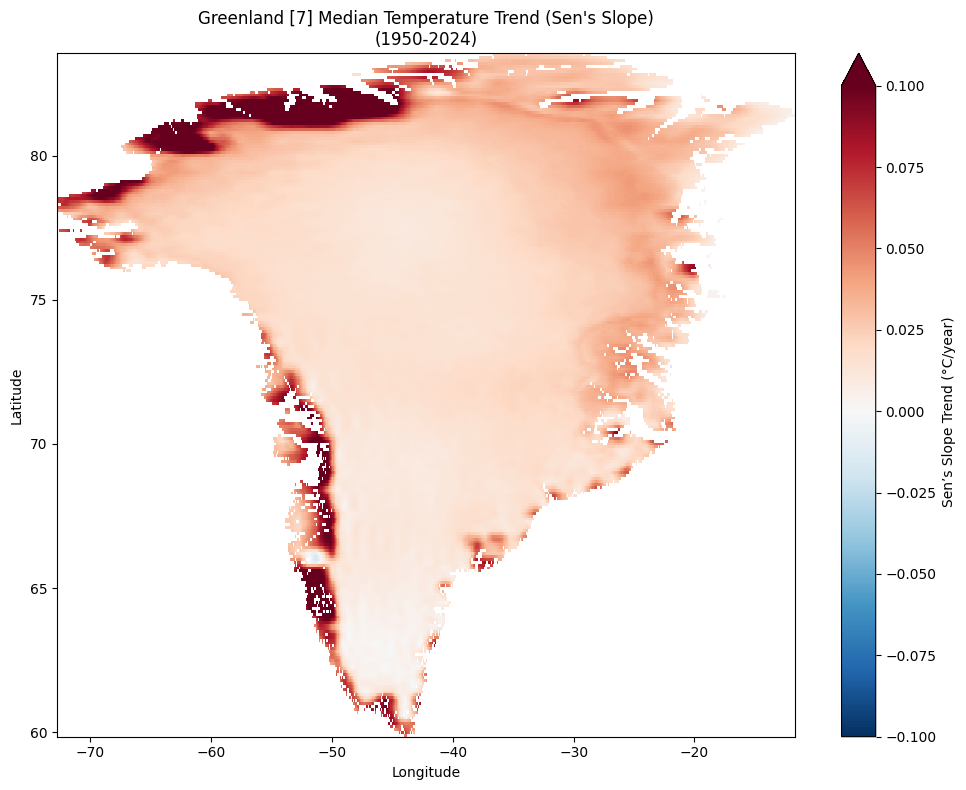

In [6]:
from itertools import combinations
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

def calculate_sens_slope(ds, varname='t2m'):
    """计算每个格点 Sen's Slope（中位趋势估计）"""
    lats = ds['latitude'].values
    lons = ds['longitude'].values
    years = ds['time.year'].values
    trend = np.full((len(lats), len(lons)), np.nan, dtype=np.float32)

    for i in range(len(lats)):
        for j in range(len(lons)):
            y = ds[varname][:, i, j].values
            if np.sum(np.isfinite(y)) > 1:
                x = years[np.isfinite(y)]
                y = y[np.isfinite(y)]

                slopes = [(y[k2] - y[k1]) / (x[k2] - x[k1])
                          for k1, k2 in combinations(range(len(x)), 2) if x[k2] != x[k1]]
                if slopes:
                    trend[i, j] = np.median(slopes)

    return xr.DataArray(
        trend,
        coords={'latitude': lats, 'longitude': lons},
        dims=['latitude', 'longitude'],
        name='Sen_Slope',
        attrs={'units': '°C/year'}
    )

# === 使用函数生成 Sen 趋势图 ===
trend_map_sen = calculate_sens_slope(ds, varname=target_variable)

plt.figure(figsize=(10, 8))
plot = trend_map_sen.plot(
    cmap='RdBu_r',
    center=0,
    vmin=-0.1,
    vmax=0.1,
    cbar_kwargs={'label': 'Sen’s Slope Trend (°C/year)'}
)
plt.title(f'Greenland {selected_months} Median Temperature Trend (Sen\'s Slope)\n({start_year_analysis}-{end_year_analysis})')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.tight_layout()
plt.savefig('Greenland_July_Sen_Slope_Trend_Map.png', dpi=300, bbox_inches='tight')
plt.show()


In [3]:
import os, glob, gc
import numpy as np
import pandas as pd
import xarray as xr
from tqdm import tqdm

# ———— 参数配置 ————
data_dir = r"F:\TUB\greenlandProject\ERA5LAND\MonthlyFeatures\1995prediction"
start_year_analysis = 1950
end_year_analysis   = 2024
target_variable     = 'ssrd'
selected_months     = [6, 7, 8]  # 夏季
# ——————————————————————

def get_spatial_grid_info():
    for year in range(start_year_analysis, end_year_analysis+1):
        for month in selected_months:
            fn = os.path.join(data_dir, f"{year:04d}{month:02d}prediction_clip.csv")
            if os.path.exists(fn):
                df = pd.read_csv(fn, usecols=['latitude','longitude'])
                return np.sort(df['latitude'].unique()), np.sort(df['longitude'].unique())
    raise FileNotFoundError("找不到任何数据文件")

def read_data_efficiently():
    lats, lons = get_spatial_grid_info()
    years = list(range(start_year_analysis, end_year_analysis+1))
    arr = np.full((len(years), len(lats), len(lons)), np.nan, dtype=np.float32)
    lat_idx = {lat:i for i,lat in enumerate(lats)}
    lon_idx = {lon:j for j,lon in enumerate(lons)}

    for yi, year in enumerate(tqdm(years, desc="加载年份")):
        dfs = []
        for m in selected_months:
            fn = os.path.join(data_dir, f"{year:04d}{m:02d}prediction_clip.csv")
            if os.path.exists(fn):
                dfs.append(pd.read_csv(fn, usecols=['latitude','longitude', target_variable]))
        if dfs:
            df_sum = pd.concat(dfs).groupby(['latitude','longitude'], as_index=False).mean()
            for _, row in df_sum.iterrows():
                i, j = lat_idx[row['latitude']], lon_idx[row['longitude']]
                arr[yi,i,j] = row[target_variable]
            del df_sum; gc.collect()

    times = pd.date_range(f"{start_year_analysis}-01-01", periods=len(years), freq='YS')
    ds = xr.Dataset(
        {target_variable: (['time','latitude','longitude'], arr)},
        coords={'time': times, 'latitude': lats, 'longitude': lons}
    )
    return ds

print("1️⃣ 读取并构建 xarray Dataset …")
ds = read_data_efficiently()

print("2️⃣ 计算夏季均值 …")
mean_map = ds[target_variable].mean(dim='time')

print("3️⃣ 转 DataFrame 并保存 CSV …")
df_mean = mean_map.to_dataframe().reset_index().rename(columns={target_variable:'mean'})
out_csv = os.path.join(data_dir, "mean_summer_ssrd.csv")
df_mean.to_csv(out_csv, index=False)
print("✅ 已保存:", out_csv)


1️⃣ 读取并构建 xarray Dataset …


加载年份: 100%|██████████| 75/75 [03:01<00:00,  2.42s/it]


2️⃣ 计算夏季均值 …
3️⃣ 转 DataFrame 并保存 CSV …
✅ 已保存: F:\TUB\greenlandProject\ERA5LAND\MonthlyFeatures\1995prediction\mean_summer_ssrd.csv


1️⃣ 读取: F:\TUB\greenlandProject\ERA5LAND\MonthlyFeatures\1995prediction\mean_summer_ssrd.csv
2️⃣ 构造透视表并绘图…


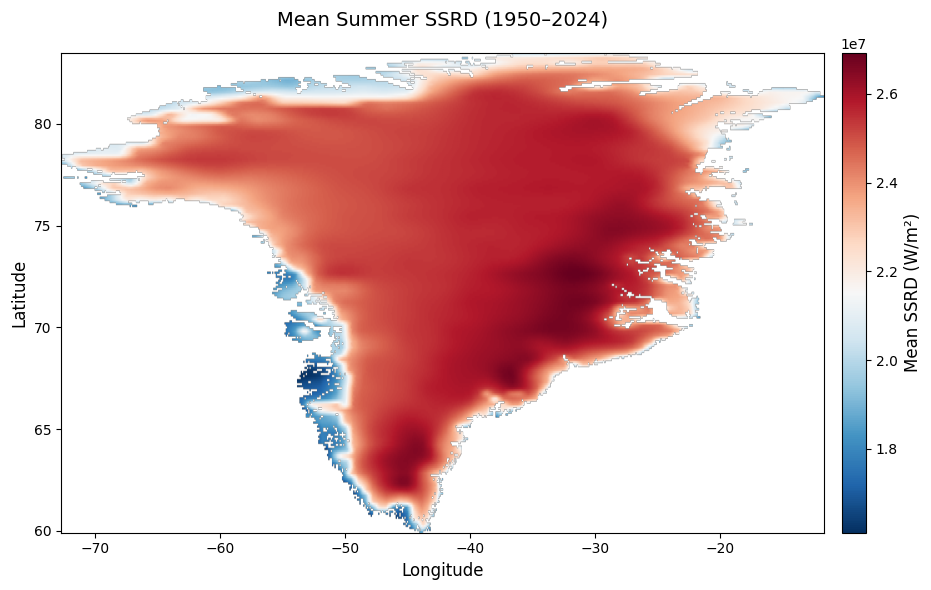

图片已保存至: F:\TUB\greenlandProject\ERA5LAND\MonthlyFeatures\1995prediction\Greenland_Summer_SSRD_Meanvalue.png


<Figure size 640x480 with 0 Axes>

In [19]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# ——— 参数配置 ———
data_dir = r"F:\TUB\greenlandProject\ERA5LAND\MonthlyFeatures\1995prediction"
csv_file = os.path.join(data_dir, "mean_summer_ssrd.csv")
# ————————————————————

print("1️⃣ 读取:", csv_file)
df = pd.read_csv(csv_file)  # 列：latitude, longitude, mean

print("2️⃣ 构造透视表并绘图…")
pivot = df.pivot(index='latitude', columns='longitude', values='mean')

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(
    pivot.values[::-1],
    cmap='RdBu_r',  # 低值蓝→高值红
    extent=[
        pivot.columns.min(), pivot.columns.max(),
        pivot.index.min(),   pivot.index.max()
    ],
    aspect='auto'
)
ax.set_title('Mean Summer SSRD (1950–2024)', fontsize=14, pad=20)
ax.set_xlabel('Longitude', fontsize=12)
ax.set_ylabel('Latitude', fontsize=12)
ax.tick_params(axis='both', which='major', labelsize=10)

cbar = plt.colorbar(im, ax=ax, shrink=1.0, pad=0.02, aspect=20)
cbar.set_label('Mean SSRD (W/m²)', fontsize=12)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()
plt.show()
# 保存图片到同一文件夹
save_path = os.path.join(data_dir, 'Greenland_Summer_SSRD_Meanvalue.png')
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"图片已保存至: {save_path}")

In [7]:
#B1. 计算并保存 Sen’s 斜率趋势（SSRD）
import os, glob, gc
import numpy as np
import pandas as pd
import xarray as xr
from scipy.stats import theilslopes
from tqdm import tqdm

# ——— 参数配置 ———
data_dir = r"F:\TUB\greenlandProject\ERA5LAND\MonthlyFeatures\1995prediction"
start_year_analysis = 1950
end_year_analysis   = 2024
target_variable     = 'ssrd'
selected_months     = [6, 7, 8]
# ——————————————————

def get_spatial_grid_info():
    for year in range(start_year_analysis, end_year_analysis + 1):
        for month in selected_months:
            fn = os.path.join(data_dir, f"{year:04d}{month:02d}prediction_clip.csv")
            if os.path.exists(fn):
                df = pd.read_csv(fn, usecols=['latitude', 'longitude'])
                return np.sort(df['latitude'].unique()), np.sort(df['longitude'].unique())
    raise FileNotFoundError("找不到任何数据文件")

def read_data_efficiently():
    lats, lons = get_spatial_grid_info()
    years = list(range(start_year_analysis, end_year_analysis + 1))
    arr = np.full((len(years), len(lats), len(lons)), np.nan, dtype=np.float32)
    lat_idx = {lat: i for i, lat in enumerate(lats)}
    lon_idx = {lon: j for j, lon in enumerate(lons)}

    for yi, year in enumerate(tqdm(years, desc="加载年份")):
        dfs = []
        for m in selected_months:
            fn = os.path.join(data_dir, f"{year:04d}{m:02d}prediction_clip.csv")
            if os.path.exists(fn):
                dfs.append(pd.read_csv(fn, usecols=['latitude','longitude', target_variable]))
        if dfs:
            df_sum = pd.concat(dfs).groupby(['latitude','longitude'], as_index=False).mean()
            for _, r in df_sum.iterrows():
                arr[yi, lat_idx[r['latitude']], lon_idx[r['longitude']]] = r[target_variable]
            del df_sum; gc.collect()

    times = pd.date_range(f"{start_year_analysis}-01-01", periods=len(years), freq='YS')
    return xr.Dataset(
        {target_variable: (['time','latitude','longitude'], arr)},
        coords={'time': times, 'latitude': lats, 'longitude': lons}
    )

def calculate_sens_slope(ds, varname='ssrd'):
    lats = ds['latitude'].values
    lons = ds['longitude'].values
    yrs  = ds['time'].dt.year.values
    trend = np.full((len(lats), len(lons)), np.nan, dtype=np.float32)

    from itertools import combinations
    for i in range(len(lats)):
        for j in range(len(lons)):
            y = ds[varname][:, i, j].values
            mask = np.isfinite(y)
            if mask.sum() > 1:
                x = yrs[mask]
                y2 = y[mask]
                slopes = [
                    (y2[b] - y2[a]) / (x[b] - x[a])
                    for a, b in combinations(range(len(x)), 2) if x[b] != x[a]
                ]
                if slopes:
                    trend[i, j] = np.median(slopes)

    return xr.DataArray(
        trend,
        coords={'latitude': lats, 'longitude': lons},
        dims=['latitude','longitude'],
        name='trend'
    )

print("1️⃣ 读取 Dataset…")
ds = read_data_efficiently()

print("2️⃣ 计算 Sen’s 斜率…")
sen = calculate_sens_slope(ds, varname=target_variable)

print("3️⃣ 转 DataFrame 并保存 CSV…")
df_sen = sen.to_dataframe().reset_index()
out_csv = os.path.join(data_dir, "ssrd_sen_slope.csv")
df_sen.to_csv(out_csv, index=False)
print("✅ 已保存:", out_csv)


1️⃣ 读取 Dataset…


加载年份: 100%|██████████| 75/75 [03:07<00:00,  2.51s/it]


2️⃣ 计算 Sen’s 斜率…
3️⃣ 转 DataFrame 并保存 CSV…
✅ 已保存: F:\TUB\greenlandProject\ERA5LAND\MonthlyFeatures\1995prediction\ssrd_sen_slope.csv


1️⃣ Reading: F:\TUB\greenlandProject\ERA5LAND\MonthlyFeatures\1995prediction\ssrd_sen_slope.csv
2️⃣ Constructing pivot table and plotting...


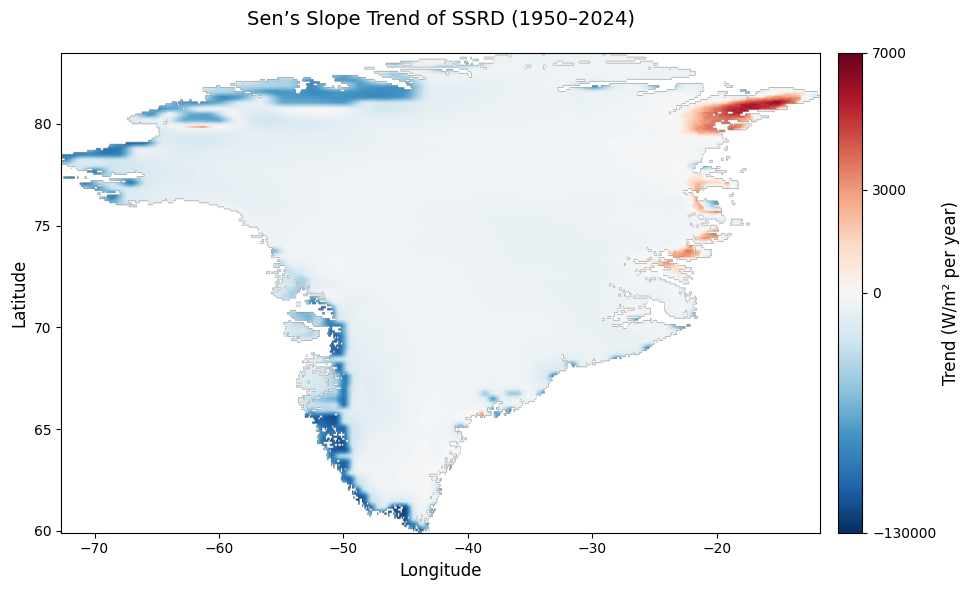

图片已保存至: F:\TUB\greenlandProject\ERA5LAND\MonthlyFeatures\1995prediction\Greenland_Summer_SSRD_Trend.png
Colobar range set to: [-130000, 7000], center point: 0


<Figure size 640x480 with 0 Axes>

In [18]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors # Import matplotlib.colors

# --- Parameter Configuration ---
data_dir = r"F:\TUB\greenlandProject\ERA5LAND\MonthlyFeatures\1995prediction"
csv_file = os.path.join(data_dir, "ssrd_sen_slope.csv")
# -----------------------------

print("1️⃣ Reading:", csv_file)
df = pd.read_csv(csv_file)  # Columns: latitude, longitude, trend

print("2️⃣ Constructing pivot table and plotting...")
pivot = df.pivot(index='latitude', columns='longitude', values='trend')

# --- Custom Colorbar Range and Normalization ---
# Define your desired minimum, maximum, and center value (usually 0)
vmin_custom = -130000
vmax_custom = 7000
vcenter = 0 # Center point for the trend, used to distinguish positive/negative

# Use TwoSlopeNorm for normalization
# `vmin` and `vmax` define the overall range of the colormap
# `vcenter` defines the neutral position in the colormap, e.g., the white or light area for 'RdBu_r'
norm = mcolors.TwoSlopeNorm(vmin=vmin_custom, vmax=vmax_custom, vcenter=vcenter)

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(
    pivot.values[::-1],
    cmap='RdBu_r', # Keep the red-increase, blue-decrease colormap
    extent=[
        pivot.columns.min(), pivot.columns.max(),
        pivot.index.min(),   pivot.index.max()
    ],
    aspect='auto',
    # --- Pass the custom norm here ---
    norm=norm
)
ax.set_title('Sen’s Slope Trend of SSRD (1950–2024)', fontsize=14, pad=20)
ax.set_xlabel('Longitude', fontsize=12)
ax.set_ylabel('Latitude', fontsize=12)
ax.tick_params(axis='both', which='major', labelsize=10)

cbar = plt.colorbar(im, ax=ax, shrink=1.0, pad=0.02, aspect=20)
cbar.set_label('Trend (W/m² per year)', fontsize=12)
cbar.ax.tick_params(labelsize=10)

# --- Add custom ticks to the colorbar ---
# Define the list of desired tick locations
custom_ticks = [-130000, 0, 3000, 7000]
cbar.set_ticks(custom_ticks)
# Optionally, you can also set custom labels if needed, but for numbers, it's often automatic
# cbar.set_ticklabels(['-130k', '0', '3k', '7k'])

plt.tight_layout()
plt.show()
# 保存图片到同一文件夹
save_path = os.path.join(data_dir, 'Greenland_Summer_SSRD_Trend.png')
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"图片已保存至: {save_path}")
print(f"Colobar range set to: [{vmin_custom}, {vmax_custom}], center point: {vcenter}")

In [1]:
# C1: 计算滑动窗口 SSRD 趋势矩阵并保存
import os, glob, gc
import numpy as np
import pandas as pd
import xarray as xr
from scipy.stats import linregress
from tqdm import tqdm

# ——— 参数配置 ———
data_dir           = r"F:\TUB\greenlandProject\ERA5LAND\MonthlyFeatures\1995prediction"
start_year         = 1950
end_year           = 2024
target_variable    = 'ssrd'
selected_months    = [6, 7, 8]
out_csv            = os.path.join(data_dir, "sliding_window_ssrd_trend.csv")
# ——————————————————

def get_spatial_grid_info():
    # 扫描第一批文件获取经纬度网格
    for yr in range(start_year, end_year+1):
        for m in selected_months:
            fn = os.path.join(data_dir, f"{yr:04d}{m:02d}prediction_clip.csv")
            if os.path.exists(fn):
                df = pd.read_csv(fn, usecols=['latitude','longitude'])
                return np.sort(df['latitude'].unique()), np.sort(df['longitude'].unique())
    raise FileNotFoundError("未找到任何匹配文件")

def read_data_efficiently():
    # 构建 time × lat × lon 的 DataArray
    lats, lons = get_spatial_grid_info()
    years = list(range(start_year, end_year+1))
    arr = np.full((len(years), len(lats), len(lons)), np.nan, dtype=np.float32)
    lat_idx = {lat:i for i,lat in enumerate(lats)}
    lon_idx = {lon:j for j,lon in enumerate(lons)}

    for yi, yr in enumerate(tqdm(years, desc="加载年份")):
        dfs = []
        for m in selected_months:
            fn = os.path.join(data_dir, f"{yr:04d}{m:02d}prediction_clip.csv")
            if os.path.exists(fn):
                dfs.append(pd.read_csv(fn, usecols=['latitude','longitude', target_variable]))
        if dfs:
            df_sum = pd.concat(dfs).groupby(['latitude','longitude'], as_index=False).mean()
            for _, r in df_sum.iterrows():
                i, j = lat_idx[r['latitude']], lon_idx[r['longitude']]
                arr[yi, i, j] = r[target_variable]
            del df_sum; gc.collect()

    times = pd.date_range(f"{start_year}-01-01", periods=len(years), freq='YS')
    return xr.Dataset(
        {target_variable: (['time','latitude','longitude'], arr)},
        coords={'time': times, 'latitude': lats, 'longitude': lons}
    )

# 1️⃣ 读取数据
print("1️⃣ 构建 xarray Dataset…")
ds = read_data_efficiently()

# 2️⃣ 计算区域平均时序
print("2️⃣ 计算全区夏季平均…")
region_mean = ds[target_variable].mean(dim=['latitude','longitude']).values
years       = ds['time.year'].values

# 3️⃣ 构建滑动窗口趋势矩阵
print("3️⃣ 构建滑动窗口趋势矩阵…")
trend_mat = pd.DataFrame(
    np.nan, index=years, columns=years, dtype=float
)
for start in tqdm(years, desc="起始年份"):
    for end in years:
        if end >= start:
            mask = (years >= start) & (years <= end)
            x = years[mask]
            y = region_mean[mask]
            valid = ~np.isnan(y)
            if valid.sum() > 1:
                slope, _, _, _, _ = linregress(x[valid], y[valid])
                trend_mat.at[start, end] = slope
            else:
                # 单年窗口趋势设为 0
                trend_mat.at[start, end] = 0.0

# 4️⃣ 保存到 CSV
print("4️⃣ 保存到：", out_csv)
trend_mat.to_csv(out_csv, float_format="%.6f")
print("✅ 已生成滑动窗口趋势矩阵，格式：")
print(trend_mat.iloc[:5, :5])  # 打印前 5×5 样例


1️⃣ 构建 xarray Dataset…


加载年份: 100%|██████████| 75/75 [03:14<00:00,  2.59s/it]


2️⃣ 计算全区夏季平均…
3️⃣ 构建滑动窗口趋势矩阵…


起始年份: 100%|██████████| 75/75 [00:00<00:00, 174.23it/s]

4️⃣ 保存到： F:\TUB\greenlandProject\ERA5LAND\MonthlyFeatures\1995prediction\sliding_window_ssrd_trend.csv
✅ 已生成滑动窗口趋势矩阵，格式：
      1950      1951      1952      1953      1954
1950   0.0 -474582.0 -237305.0 -146552.2 -264666.0
1951   NaN       0.0     -28.0   -6958.0 -253925.8
1952   NaN       NaN       0.0  -13888.0 -420881.0
1953   NaN       NaN       NaN       0.0 -827874.0
1954   NaN       NaN       NaN       NaN       0.0


2️⃣ 计算色标范围…
3️⃣ 绘图 & 翻转 Y 轴到右上角…


NameError: name 'save_path' is not defined

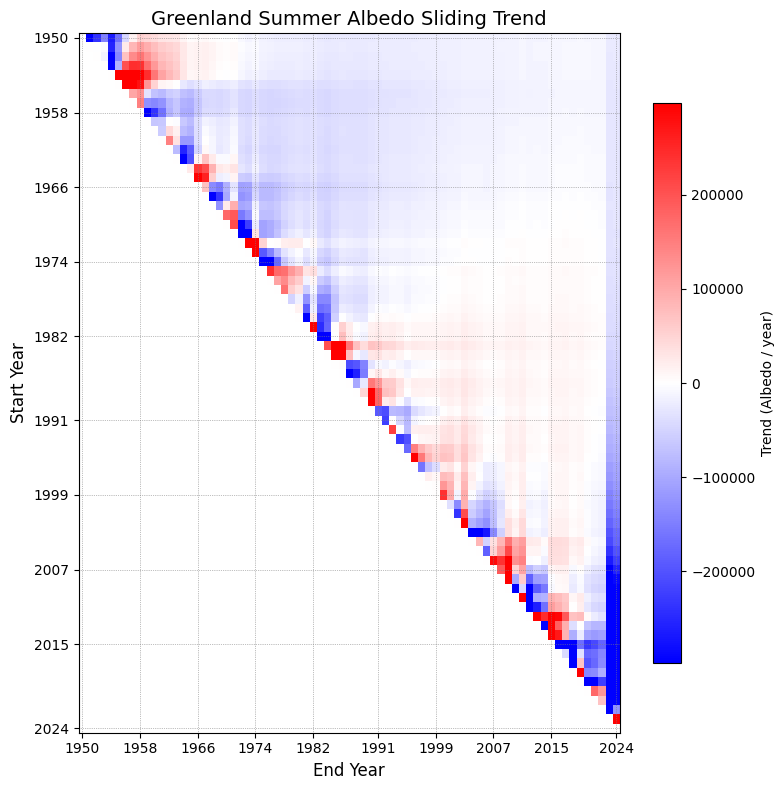

In [4]:
#C2显示有问题，参考这个改一下print("1️⃣ 读取矩阵 CSV：", csv_file)
# 第一列 (索引) 是 Start Year，第一行 (列名) 是 End Year。
trend_mat = pd.read_csv(csv_file, index_col=0)

# 获取起始年和结束年列表
start_years = trend_mat.index.astype(int).values
end_years   = trend_mat.columns.astype(int).values

print("2️⃣ 计算色标范围…")
data_vals = np.ma.masked_invalid(trend_mat.values).compressed()
if data_vals.size > 0:
    p2  = np.percentile(data_vals, 2)
    p98 = np.percentile(data_vals, 98)
    M   = max(abs(p2), abs(p98))
    vmin_final, vmax_final = -M, M
else:
    print("⚠️ 无有效数据，使用默认色标")
    vmin_final, vmax_final = -0.01, 0.01

print("3️⃣ 绘图 & 翻转 Y 轴到右上角…")
fig, ax = plt.subplots(figsize=(8, 8))

# 掩盖 NaN
data_for_plot = np.ma.masked_invalid(trend_mat.values)

im = ax.imshow(
    data_for_plot,
    cmap='bwr',
    vmin=vmin_final, vmax=vmax_final,
    extent=[
        end_years.min() - 0.5, end_years.max() + 0.5,
        start_years.min() - 0.5, start_years.max() + 0.5
    ],
    origin='lower',   # 保持 'lower'
    aspect='auto'
)

# —— 关键：把 Y 轴倒过来 —— 
ax.invert_yaxis()

# 坐标和标签
ax.set_xlabel('End Year', fontsize=12)
ax.set_ylabel('Start Year', fontsize=12)
ax.set_title('Greenland Summer Albedo Sliding Trend', fontsize=14)

# 颜色条
cbar = plt.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label('Trend (Albedo / year)', fontsize=10)

# 刻度
num_ticks = 10
xticks = np.linspace(end_years.min(), end_years.max(), num_ticks, dtype=int)
yticks = np.linspace(start_years.min(), start_years.max(), num_ticks, dtype=int)
ax.set_xticks(xticks)
ax.set_yticks(yticks)
ax.tick_params(axis='both', which='major', labelsize=10)

# 网格
ax.grid(which='major', color='grey', linestyle=':', linewidth=0.5)

plt.tight_layout()

# 保存并展示
#save_path = os.path.join(data_dir, 'Greenland_SummerAlbedo_Sliding_Trend.png')
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()
print("🎨 热力图已保存至：", save_path)